<a href="https://colab.research.google.com/github/kemal1308/TugasBesarBigData-hm/blob/main/notebooks/02_run_ml_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# 1. Clone repositori dari GitHub
!git clone https://github.com/kemal1308/TugasBesarBigData-hm.git

# 2. Pindah direktori kerja ke dalam folder proyek
%cd TugasBesarBigData-hm

Cloning into 'TugasBesarBigData-hm'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (100/100), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 100 (delta 38), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (100/100), 36.07 KiB | 5.15 MiB/s, done.
Resolving deltas: 100% (38/38), done.
/content/TugasBesarBigData-hm


In [6]:
!ls -la

total 40
drwxr-xr-x 7 root root 4096 Nov  3 03:50 .
drwxr-xr-x 1 root root 4096 Nov  3 03:50 ..
drwxr-xr-x 2 root root 4096 Nov  3 03:50 data
drwxr-xr-x 8 root root 4096 Nov  3 03:50 .git
-rw-r--r-- 1 root root   69 Nov  3 03:50 .gitignore
-rw-r--r-- 1 root root 2355 Nov  3 03:50 main_ml.py
drwxr-xr-x 2 root root 4096 Nov  3 03:50 models
drwxr-xr-x 2 root root 4096 Nov  3 03:50 notebooks
-rw-r--r-- 1 root root  337 Nov  3 03:50 README.md
drwxr-xr-x 2 root root 4096 Nov  3 03:50 src


In [7]:
!pip install pyspark -q

In [8]:
import sys
from src.config import ALS_PARAMS
from src.preprocessing import create_implicit_ratings

print("Modul berhasil dimuat!")

Modul berhasil dimuat!


In [9]:
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("CekData").getOrCreate()

# Path jika Anda menambahkan pintasan folder 'Dataset_HM':
path_dataset_hm = "/content/drive/MyDrive/Dataset_HM/cleaned_data.parquet"

# Path jika Anda langsung menambahkan pintasan 'cleaned_data.parquet':
path_parquet_langsung = "/content/drive/MyDrive/cleaned_data.parquet"

# Coba baca salah satunya
try:
    df = spark.read.parquet(path_dataset_hm)
    print("Berhasil membaca via folder Dataset_HM!")
except:
    df = spark.read.parquet(path_parquet_langsung)
    print("Berhasil membaca via shortcut langsung!")

print(f"Total data baris: {df.count()}")
df.printSchema()

Mounted at /content/drive
Berhasil membaca via folder Dataset_HM!
Total data baris: 31788324
root
 |-- article_id: integer (nullable = true)
 |-- t_dat: date (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- price: double (nullable = true)
 |-- sales_channel_id: integer (nullable = true)
 |-- product_code: integer (nullable = true)
 |-- prod_name: string (nullable = true)
 |-- product_type_no: integer (nullable = true)
 |-- product_type_name: string (nullable = true)
 |-- product_group_name: string (nullable = true)
 |-- graphical_appearance_no: integer (nullable = true)
 |-- graphical_appearance_name: string (nullable = true)
 |-- colour_group_code: integer (nullable = true)
 |-- colour_group_name: string (nullable = true)
 |-- perceived_colour_value_id: integer (nullable = true)
 |-- perceived_colour_value_name: string (nullable = true)
 |-- perceived_colour_master_id: integer (nullable = true)
 |-- perceived_colour_master_name: string (nullable = true)
 |-- departmen

In [6]:
#ini tadinya buat nyambungin ulang  karena ga semua akses gdrive disetujui, taapi kalo
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [10]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

# 1. Konfigurasi Spark Session
spark = SparkSession.builder \
    .appName("HM_Recommendation_Colab") \
    .config("spark.driver.memory", "10g") \
    .config("spark.executor.memory", "10g") \
    .config("spark.sql.shuffle.partitions", "100") \
    .getOrCreate()

# 2. Lokasi dataset di Drive (sesuaikan nama foldernya)
parquet_path = "/content/drive/MyDrive/Dataset_HM/cleaned_data.parquet"
df_raw = spark.read.parquet(parquet_path)

# 3. Filter transaksi 2 bulan terakhir agar komputasi efisien dan relevan
if "t_dat" in df_raw.columns:
    df_active = df_raw.filter(F.col("t_dat") >= "2020-08-01")
else:
    df_active = df_raw.sample(fraction=0.1, seed=42)

print(f"Dataset berhasil dimuat! Total baris aktif: {df_active.count()}")
df_active.printSchema()

Dataset berhasil dimuat! Total baris aktif: 2035461
root
 |-- article_id: integer (nullable = true)
 |-- t_dat: date (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- price: double (nullable = true)
 |-- sales_channel_id: integer (nullable = true)
 |-- product_code: integer (nullable = true)
 |-- prod_name: string (nullable = true)
 |-- product_type_no: integer (nullable = true)
 |-- product_type_name: string (nullable = true)
 |-- product_group_name: string (nullable = true)
 |-- graphical_appearance_no: integer (nullable = true)
 |-- graphical_appearance_name: string (nullable = true)
 |-- colour_group_code: integer (nullable = true)
 |-- colour_group_name: string (nullable = true)
 |-- perceived_colour_value_id: integer (nullable = true)
 |-- perceived_colour_value_name: string (nullable = true)
 |-- perceived_colour_master_id: integer (nullable = true)
 |-- perceived_colour_master_name: string (nullable = true)
 |-- department_no: integer (nullable = true)
 |-- depa

In [11]:
from src.preprocessing import create_implicit_ratings, fit_and_transform_indexers

# 1. Bentuk matriks interaksi (purchase_count sebagai implicit rating)
interactions = create_implicit_ratings(df_active)

# 2. Siapkan direktori penyimpanan artefak di Google Drive
MODEL_DIR = "/content/drive/MyDrive/Dataset_HM/models"

# 3. StringIndexer Pipeline (mengubah ID hash menjadi integer)
indexed_df, indexer_model = fit_and_transform_indexers(
    interactions,
    model_save_path=f"{MODEL_DIR}/string_indexer_pipeline"
)

# 4. Train-Test Split (80% train, 20% test)
train_df, test_df = indexed_df.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

print(f"Data Train: {train_df.count()} baris | Data Test: {test_df.count()} baris")

Data Train: 1434653 baris | Data Test: 358961 baris


In [12]:
from src.model import train_als_model
from src.config import ALS_PARAMS

print("Melatih model ALS di Google Colab...")
als_model = train_als_model(
    train_df,
    ALS_PARAMS,
    save_path=f"{MODEL_DIR}/als_recommender_model"
)
print("Pelatihan selesai! Artefak model berhasil disimpan di Google Drive.")

Melatih model ALS di Google Colab...
>> Proses fitting model ALS sedang berjalan...
>> Model ALS berhasil disimpan ke: /content/drive/MyDrive/Dataset_HM/models/als_recommender_model
Pelatihan selesai! Artefak model berhasil disimpan di Google Drive.


In [13]:
from src.model import evaluate_model

# 1. Hitung nilai RMSE
rmse = evaluate_model(als_model, test_df)

print(f"==========================================")
print(f">> Hasil Evaluasi Test RMSE: {rmse:.4f}")
print(f"==========================================")

# 2. Tampilkan sampel prediksi versus nilai aktual
predictions = als_model.transform(test_df)
predictions.select("user_idx", "item_idx", "purchase_count", "prediction").show(10)

>> Hasil Evaluasi Test RMSE: 1.0794
+--------+--------+--------------+------------+
|user_idx|item_idx|purchase_count|  prediction|
+--------+--------+--------------+------------+
|       1|    9788|           1.0|  0.03805856|
|       1|    9870|           1.0| 0.038775414|
|       1|   19042|           1.0|0.0021628689|
|       1|   14221|           1.0|0.0125328945|
|       1|    6295|           2.0|  0.12546961|
|       1|    5291|           2.0| 0.055565096|
|       1|   17539|           1.0|0.0068077752|
|       1|    4160|           1.0|  0.16300659|
|       1|    4313|           1.0|  0.30301768|
|       1|   27026|           2.0| 8.983094E-5|
+--------+--------+--------------+------------+
only showing top 10 rows


In [14]:
# Ambil sampel user unik dari data test
sample_users = test_df.select("user_idx").distinct().limit(10)

# Hasilkan Top 5 rekomendasi produk
recommendations = als_model.recommendForUserSubset(sample_users, 5)

recommendations.show(truncate=False)

+--------+----------------------------------------------------------------------------------------------+
|user_idx|recommendations                                                                               |
+--------+----------------------------------------------------------------------------------------------+
|4101    |[{247, 0.8873596}, {257, 0.87636614}, {261, 0.8662197}, {245, 0.8494795}, {545, 0.7961496}]   |
|87071   |[{59, 0.58101815}, {21, 0.57145774}, {97, 0.4457516}, {45, 0.43463397}, {164, 0.42367977}]    |
|140541  |[{77, 0.73838365}, {135, 0.70688677}, {206, 0.44670835}, {130, 0.44110802}, {110, 0.43846682}]|
|57394   |[{32, 0.73140633}, {140, 0.6119451}, {325, 0.60009867}, {311, 0.57165396}, {24, 0.56890255}]  |
|22305   |[{140, 0.80785275}, {159, 0.79022104}, {0, 0.77660716}, {96, 0.74495494}, {55, 0.71419376}]   |
|1037    |[{406, 1.095372}, {462, 1.0740644}, {144, 1.0736922}, {301, 1.0602287}, {71, 1.0259833}]      |
|84737   |[{33, 0.6514156}, {76, 0.592873}, {2

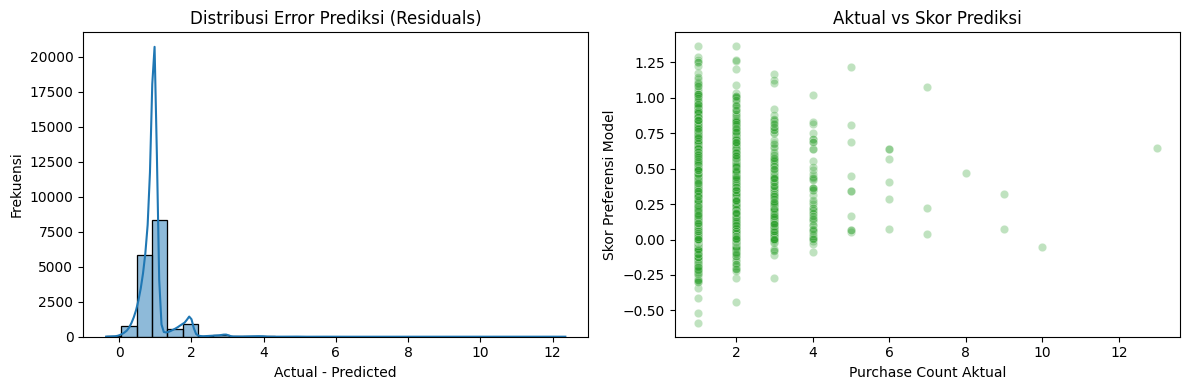

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil sampel prediksi untuk plotting
pred_sample = predictions.select("purchase_count", "prediction") \
    .filter(F.col("prediction").isNotNull()) \
    .sample(fraction=0.05, seed=42) \
    .toPandas()

pred_sample["residual_error"] = pred_sample["purchase_count"] - pred_sample["prediction"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(pred_sample["residual_error"], bins=30, kde=True, color="#1f77b4")
plt.title("Distribusi Error Prediksi (Residuals)")
plt.xlabel("Actual - Predicted")
plt.ylabel("Frekuensi")

plt.subplot(1, 2, 2)
sns.scatterplot(x="purchase_count", y="prediction", data=pred_sample, alpha=0.3, color="#2ca02c")
plt.title("Aktual vs Skor Prediksi")
plt.xlabel("Purchase Count Aktual")
plt.ylabel("Skor Preferensi Model")

plt.tight_layout()
plt.savefig("grafik_evaluasi_als.png", dpi=300)
plt.show()

In [16]:
#Reverse Mapping: Tampilkan Nama Produk Asli

# 1. Ambil model StringIndexer artikel untuk mendapatkan mapping item_idx -> article_id
article_indexer_model = indexer_model.stages[1]  # stage 0: user, stage 1: item
labels = article_indexer_model.labels

# 2. Buat mapping DataFrame kecil untuk item_idx ke article_id
from pyspark.sql.types import StructType, StructField, IntegerType, StringType
mapping_data = [(idx, labels[idx]) for idx in range(len(labels))]
df_item_mapping = spark.createDataFrame(mapping_data, ["item_idx", "article_id"])

# 3. Explode recommendations Top-5 agar menjadi baris tabular
from pyspark.sql.functions import explode, col
recs_exploded = recommendations.select(
    col("user_idx"),
    explode(col("recommendations")).alias("rec")
).select(
    col("user_idx"),
    col("rec.item_idx").alias("item_idx"),
    col("rec.rating").alias("predicted_score")
)

# 4. Join dengan metadata produk dari df_raw
recs_with_meta = recs_exploded \
    .join(df_item_mapping, on="item_idx", how="left") \
    .join(
        df_raw.select("article_id", "prod_name", "product_type_name", "product_group_name").dropDuplicates(["article_id"]),
        on="article_id",
        how="left"
    )

print(">> Sampel Rekomendasi Berbasis Nama Produk Asli:")
recs_with_meta.select("user_idx", "article_id", "prod_name", "product_type_name", "predicted_score") \
    .orderBy("user_idx", col("predicted_score").desc()) \
    .show(15, truncate=False)

>> Sampel Rekomendasi Berbasis Nama Produk Asli:
+--------+----------+----------------------------+-----------------+---------------+
|user_idx|article_id|prod_name                   |product_type_name|predicted_score|
+--------+----------+----------------------------+-----------------+---------------+
|1037    |935892001 |LW (J) Conc PRICE SWEATSHIRT|Bra              |1.095372       |
|1037    |936622001 |LW (J) consc PRICE jogger   |Pyjama bottom    |1.0740644      |
|1037    |920610001 |Peking oversized            |Blazer           |1.0736922      |
|1037    |794575017 |Sascha pullover hoodie      |Hoodie           |1.0602287      |
|1037    |547780003 |Basic sweatpants            |Trousers         |1.0259833      |
|4101    |861558002 |Meringue                    |Dress            |0.8873596      |
|4101    |717727014 |Mel maxi dress  W           |Dress            |0.87636614     |
|4101    |739819010 |Polly strap dress           |Dress            |0.8662197      |
|4101    |835008